# Leave-one-cancer-type-out analysis (pan-cancer task, no_deep cohort)

Design (`slurm/submit_loco.sh`, `src/comp/build_loco_splits.py`): for each cancer type, the best-model
search (feature type × classifier × number of TSSs, 10-fold CV) runs on the 130 training healthy donors
and the six other types; the selected model is refitted, its 95%-specificity threshold frozen from the
search's held-out scores, and it is applied once to all patients of the left-out type and to 34 held-out
healthy donors (the same for every type).

- (a) AUROC of the left-out type against the 34 held-out donors (participant bootstrap 95% interval), next
  to the AUROC of the same samples in the fully nested pan-cancer CV, where the type is in training;
- (b) AUROC on the left-out type when one fixed model (the configuration every search selected) uses only
  the highest-ranked TSSs, ranked over all training types together (pooled) or within every training type
  with the ranks averaged (consensus) (`export/export_fig4_loco_rankings.py`); bars = mean of the seven types.
- Separate file `fig4_loco_scores.png`: scores of the held-out donors and of each left-out type, with the
  frozen thresholds.

Source data: `export/export_fig4_loco.py` -> `data/no_deep/fig4_loco_{per_type,predictions,ksweep}.csv`,
`fig4_loco_summary.json`; `fig4_loco_rankings.csv` (`export/export_fig4_loco_rankings.py`).

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

COHORT = "no_deep"   # the leave-one-cancer-type-out runs exist for this cohort only
_DATA = os.path.join("data", COHORT)
_OUT = os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run python src/figures/export/export_fig4_loco.py"
    return p


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

per_type = pd.read_csv(data_path("fig4_loco_per_type.csv"))
pred = pd.read_csv(data_path("fig4_loco_predictions.csv"))
ks = pd.read_csv(data_path("fig4_loco_ksweep.csv"))                 # the search's winner per k (numbers cell only)
loco_rank = pd.read_csv(data_path("fig4_loco_rankings.csv"))        # panel c (export_fig4_loco_rankings.py)
with open(data_path("fig4_loco_summary.json")) as fh:
    summary = json.load(fh)

TYPE_ORDER = per_type["type"].tolist()          # the exporter's order: by number of patients
LABEL = per_type.set_index("type")["label"].to_dict()
DD, HEALTHY = "#0173B2", "#2E8B57"              # the data-driven model and the healthy donors
display(per_type[["label", "n_cancer", "feature", "classifier", "n_tss", "training_cv_auc", "auc", "auc_lo", "auc_hi",
                  "auc_in_training", "sensitivity", "specificity"]].round(3))


,label,n_cancer,feature,classifier,n_tss,training_cv_auc,auc,auc_lo,auc_hi,auc_in_training,sensitivity,specificity
0,Breast,54,griffin_diff,Logistic Regression,15000,0.959,0.979,0.951,0.996,0.978,0.815,0.971
1,Pancreatic,34,griffin_diff,Logistic Regression,15000,0.978,0.798,0.689,0.896,0.935,0.294,0.941
2,Ovarian,28,griffin_diff,Logistic Regression,15000,0.966,0.982,0.947,1.000,0.987,0.893,0.941
3,Gastric,27,griffin_diff,Logistic Regression,15000,0.968,0.967,0.926,0.996,0.973,0.815,0.941
4,Colorectal,26,griffin_diff,Logistic Regression,15000,0.975,0.958,0.906,0.992,0.962,0.731,0.941
5,Bile duct,24,griffin_diff,Logistic Regression,15000,0.970,0.968,0.924,0.998,0.977,0.833,0.882
6,Lung,10,griffin_diff,Logistic Regression,15000,0.962,1.000,1.000,1.000,1.000,1.000,0.912


## Panels

In [2]:
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#CC6677", "#882255", "#AA4499", "#DDCC77", "#999933", "#44AA99", "#88CCEE"]))   # one colour per cancer type
RANK_COLORS = ("#0173B2", "#029E73")
LIGHT = {"#DDCC77", "#88CCEE", "#44AA99", "#999933"}   # bars on which the value is written in black


def panel_auc(ax):
    """a: AUROC per left-out type (one colour per type), with the same patients and donors in the nested
    pan-cancer cross-validation, where the type is in training, as a reference."""
    x = np.arange(len(per_type))
    a = per_type["auc"].to_numpy()
    cols = [TYPE_COLORS[t] for t in TYPE_ORDER]
    ax.bar(x - 0.12, a, 0.5, yerr=[a - per_type["auc_lo"], per_type["auc_hi"] - a], color=cols, capsize=3,
           error_kw={"elinewidth": 1.1})
    r = per_type["auc_in_training"].to_numpy()
    ax.errorbar(x + 0.3, r, yerr=[r - per_type["auc_in_training_lo"], per_type["auc_in_training_hi"] - r], fmt="D", color="white",
                markeredgecolor="black", markersize=6.5, ecolor="0.35", elinewidth=1, capsize=2.5)
    for xi, v, c in zip(x, a, cols):
        ax.text(xi - 0.12, 0.515, f"{v:.2f}", ha="center", va="bottom", color="black" if c in LIGHT else "white", fontsize=9.5, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{l}\n(n = {n})" for l, n in zip(per_type["label"], per_type["n_cancer"])], fontsize=10)
    ax.set_ylim(0.5, 1.03)
    ax.set_ylabel("AUROC against the 34 held-out healthy donors\n(error bars = 95% bootstrap interval)", fontsize=12)
    ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True); ax.tick_params(axis="y", labelsize=11)
    ax.legend(handles=[Patch(facecolor="0.55", label="cancer type left out of training"),
                       Line2D([], [], marker="D", ls="none", markerfacecolor="white", markeredgecolor="black", markersize=6.5,
                              label="cancer type in training (nested cross-validation)")],
              fontsize=9.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1)


def panel_scores(ax):
    """b: scores of the patients of each left-out type under the model that never saw that type, next to the
    34 held-out healthy donors (their scores under all seven models together)."""
    rng = np.random.default_rng(0)

    def violin(x, v, col, s):
        vp = ax.violinplot([v], positions=[x], widths=0.7, showextrema=False)
        for b in vp["bodies"]:
            b.set_facecolor(col); b.set_edgecolor("none"); b.set_alpha(0.35)
        ax.scatter(x + rng.uniform(-0.13, 0.13, len(v)), v, s=s, color=col, edgecolor="black", linewidth=0.25, alpha=0.85, zorder=3)
        ax.hlines(np.median(v), x - 0.25, x + 0.25, color="black", linewidth=1.8, zorder=4)

    thr = per_type.set_index("type")["threshold_95spec_train"]
    for v in thr:                                    # healthy column: the thresholds of all seven models
        ax.hlines(v, -0.38, 0.38, color="0.2", linestyle="--", linewidth=0.8, zorder=5)
    violin(0, pred.loc[pred["y_true"] == 0, "score"].to_numpy(), "0.55", 5)
    for i, t in enumerate(TYPE_ORDER, start=1):
        violin(i, pred.loc[(pred["type"] == t) & (pred["y_true"] == 1), "score"].to_numpy(), TYPE_COLORS[t], 11)
        ax.hlines(thr[t], i - 0.38, i + 0.38, color="0.1", linestyle="--", linewidth=1.5, zorder=5)   # this model's threshold
    ax.axvline(0.5, color="0.6", lw=0.8)
    ax.set_xticks(range(len(TYPE_ORDER) + 1))
    ax.set_xticklabels(["Healthy\n(held out)"] + [LABEL[t] for t in TYPE_ORDER], fontsize=10)
    ax.set_xlim(-0.6, len(TYPE_ORDER) + 0.6); ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel("Predicted probability of cancer", fontsize=12)
    ax.tick_params(axis="y", labelsize=11)
    ax.legend(handles=[Line2D([], [], color="0.1", ls="--", lw=1.5, label="threshold of each model: above the line = called cancer")],
              fontsize=9.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14))


def panel_rankings(ax):
    """AUROC on the left-out type when the model may use only the best-scoring TSSs (one fixed model, the
    configuration every search selected). TSSs are scored on the training samples in two ways: over all
    training cancer types together, or within every training type separately (must score well in each).
    Bars: mean of the seven left-out types; dots: the single types, in the colours of the first panel."""
    ks_show = [100, 1000, 5000]
    allr = loco_rank[loco_rank["ranking"] == "all"].set_index("type")
    rng = np.random.default_rng(1)

    def bar(x, vals, col, width=0.36):
        ax.bar(x, np.mean(vals), width, color=col, alpha=0.85, zorder=2)
        ax.text(x, 0.515, f"{np.mean(vals):.2f}", ha="center", va="bottom", color="white", fontsize=10, fontweight="bold", zorder=4)
        ax.scatter(x + rng.uniform(-0.1, 0.1, len(vals)), vals, s=30, color=[TYPE_COLORS[t] for t in TYPE_ORDER],
                   edgecolor="black", linewidth=0.5, zorder=3)

    for gi, k in enumerate(ks_show):
        for off, ranking, col in [(-0.2, "pooled", RANK_COLORS[0]), (0.2, "consensus", RANK_COLORS[1])]:
            g = loco_rank[(loco_rank["ranking"] == ranking) & (loco_rank["k"] == k)].set_index("type")
            bar(gi + off, g.loc[TYPE_ORDER, "auc"].to_numpy(), col)
    bar(len(ks_show), allr.loc[TYPE_ORDER, "auc"].to_numpy(), "0.4", width=0.5)
    ax.set_xticks(range(len(ks_show) + 1))
    ax.set_xticklabels([f"best {k:,}" for k in ks_show] + [f"all {int(allr['k'].iloc[0]):,}"], fontsize=11)
    ax.set_xlabel("TSSs the model may use", fontsize=12)
    ax.set_ylim(0.5, 1.03)
    ax.set_ylabel("AUROC on the left-out cancer type", fontsize=12)
    ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True); ax.tick_params(axis="y", labelsize=11)
    ax.legend(handles=[Patch(facecolor=RANK_COLORS[0], alpha=0.85, label="best-scoring over all training cancer types together"),
                       Patch(facecolor=RANK_COLORS[1], alpha=0.85, label="best-scoring in every training cancer type (consistent TSSs)"),
                       Line2D([], [], marker="o", ls="none", markerfacecolor="0.8", markeredgecolor="black", markersize=6,
                              label="single left-out cancer types (colours as in the first panel); bars: their mean")],
              fontsize=9.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1)


## Assemble the figure

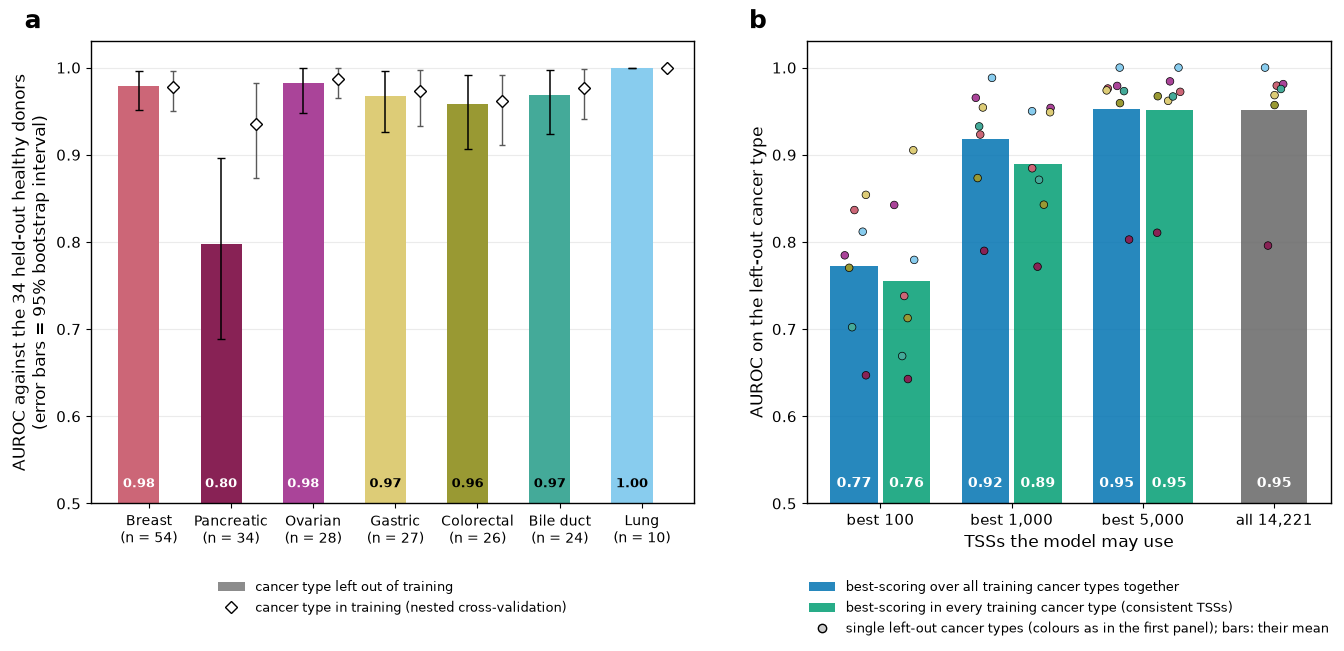

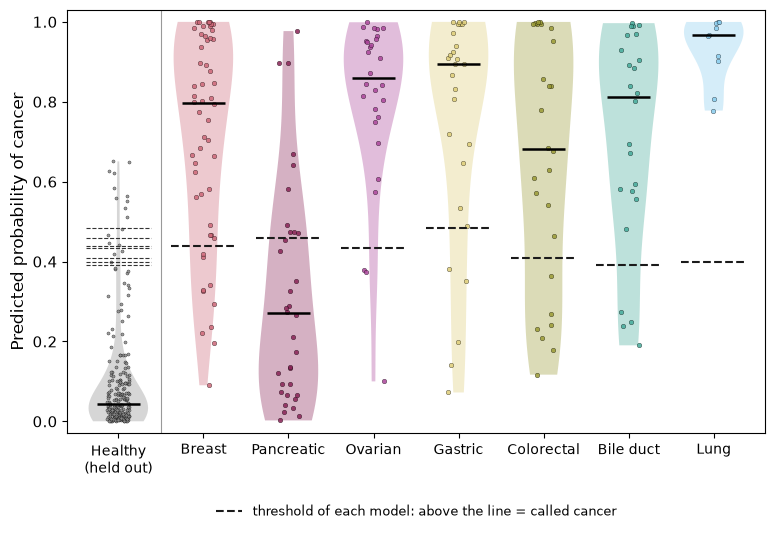

In [3]:
LETTERS = "ab"   # the score violins (panel_scores) are drawn separately below
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.2})
panel_auc(axes[0])
panel_rankings(axes[1])
for ax, letter in zip(axes, LETTERS):
    ax.text(-0.11, 1.07, letter, transform=ax.transAxes, fontsize=18, fontweight="bold", va="top")
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.0); spine.set_color("black")
fig.savefig(os.path.join(_OUT, "fig4_loco.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(_OUT, "fig4_loco.pdf"), bbox_inches="tight")
plt.show()

# the score distributions per left-out type (separate figure)
fig, ax = plt.subplots(figsize=(9, 5.5))
panel_scores(ax)
fig.savefig(os.path.join(_OUT, "fig4_loco_scores.png"), dpi=300, bbox_inches="tight")
plt.show()


## Summary numbers

In [4]:
print("Per left-out type (AUROC [95% bootstrap interval]; in training = nested pan-cancer CV, same patients and donors):")
for _, r in per_type.iterrows():
    print(f"  {r['label']:10s} n = {int(r['n_cancer']):2d}: left out {r['auc']:.3f} [{r['auc_lo']:.2f}-{r['auc_hi']:.2f}] | in training {r['auc_in_training']:.3f} "
          f"[{r['auc_in_training_lo']:.2f}-{r['auc_in_training_hi']:.2f}] | sensitivity {int(r['tp'])}/{int(r['n_cancer'])} = {r['sensitivity']:.2f} "
          f"[{r['sensitivity_lo']:.2f}-{r['sensitivity_hi']:.2f}], specificity {int(r['tn'])}/{int(r['n_healthy'])} = {r['specificity']:.2f}")
print("\nSelected configuration per search:", summary["configurations"])
print(f"Mean AUROC over the seven types: left out {summary['auc_mean_over_types']:.3f}, in training {summary['auc_in_training_mean_over_types']:.3f} "
      f"(weighted by patients: {summary['auc_mean_weighted_by_n']:.3f} and {summary['auc_in_training_mean_weighted_by_n']:.3f})")
s = summary["sensitivity_at_frozen_threshold"]
print(f"Sensitivity at the frozen threshold, all types: {s['tp']}/{s['n']} = {s['value']:.3f} [{s['ci95'][0]:.2f}-{s['ci95'][1]:.2f}]")
print("\nPanel c, fixed model, mean AUROC over the seven types (pooled vs consensus ranking; all TSSs):")
print(loco_rank.groupby(["ranking", "k"])["auc"].mean().unstack(0).round(3).to_string())
print("\nPanel c per type:")
print(loco_rank[loco_rank["ranking"] != "all"].pivot_table(index="label", columns=["k", "ranking"], values="auc").round(2).to_string())
print("\nNot drawn: the search's winner at every number of TSSs (rows = k):")
print(ks.pivot(index="k", columns="label", values="auc")[list(per_type["label"])].assign(mean=lambda d: d.mean(axis=1)).round(3).to_string())
print("\nWinner of the search at every k (feature / classifier), per type:")
print(ks.assign(cfg=ks["feature"] + " / " + ks["classifier"]).pivot(index="k", columns="label", values="cfg")[list(per_type["label"])].to_string())


Per left-out type (AUROC [95% bootstrap interval]; in training = nested pan-cancer CV, same patients and donors):
  Breast     n = 54: left out 0.979 [0.95-1.00] | in training 0.978 [0.95-1.00] | sensitivity 44/54 = 0.81 [0.69-0.91], specificity 33/34 = 0.97
  Pancreatic n = 34: left out 0.798 [0.69-0.90] | in training 0.935 [0.87-0.98] | sensitivity 10/34 = 0.29 [0.15-0.47], specificity 32/34 = 0.94
  Ovarian    n = 28: left out 0.982 [0.95-1.00] | in training 0.987 [0.97-1.00] | sensitivity 25/28 = 0.89 [0.72-0.98], specificity 32/34 = 0.94
  Gastric    n = 27: left out 0.967 [0.93-1.00] | in training 0.973 [0.93-1.00] | sensitivity 22/27 = 0.81 [0.62-0.94], specificity 32/34 = 0.94
  Colorectal n = 26: left out 0.958 [0.91-0.99] | in training 0.962 [0.91-0.99] | sensitivity 19/26 = 0.73 [0.52-0.88], specificity 32/34 = 0.94
  Bile duct  n = 24: left out 0.968 [0.92-1.00] | in training 0.977 [0.94-1.00] | sensitivity 20/24 = 0.83 [0.63-0.95], specificity 30/34 = 0.88
  Lung       n =